In [148]:
import open3d as o3d
import numpy as np
from PIL import Image, ImageFilter
import matplotlib.pyplot as plt

In [149]:
mask_path = "mask_instance/mask_instance_0.png"
ply_filename = "ov7670_point_cloud.ply"
padding_size = 11

In [150]:
with open(ply_filename, 'r', encoding='utf-8', errors='ignore') as f:
        header = []
        num_vertex = 0
        has_color = False
        for line in f:
            header.append(line.strip())
            if line.startswith('element vertex'):
                num_vertex = int(line.split()[-1])
            if line.startswith('property uchar r') or line.startswith('property float r'):
                has_color = True
            if line.startswith('end_header'):
                break
                
with open(ply_filename, 'rb') as f:
    for _ in range(len(header)): f.readline()
    try:
        data = np.loadtxt(f, max_rows=num_vertex)
    except ValueError:
        f.seek(0)
        for _ in range(len(header)): f.readline()
        data = np.frombuffer(f.read(), dtype=np.float32).reshape(num_vertex, -1)
            
points = data[:, 0:3]
colors = data[:, 3:6] / 255.0 if has_color and data.shape[0] >= 6 else None

In [ ]:
mask = Image.open(mask_path).convert("L")
padded_mask = mask.filter(ImageFilter.MaxFilter(size=padding_size))
print(mask.getdata)
mask_rotated = padded_mask.rotate(90, expand=True)

print(mask_rotated.getdata)
mask_np = np.array(mask_rotated)
mask_flat = mask_np.flatten()

mask_condition = mask_flat > 0
valid_depth_condition = ~np.isnan(points[:, 2]) & (points[:, 2] != 0) & np.isfinite(points[:, 2])
final_keep_indices = mask_condition & valid_depth_condition

# 7. Create clean isolated cloud
print(final_keep_indices)
print(valid_depth_condition)
filtered_points = points[final_keep_indices]
all_points = points[valid_depth_condition]
filtered_pcd = o3d.geometry.PointCloud()
complete_pcd = o3d.geometry.PointCloud()
complete_pcd.points = o3d.utility.Vector3dVector(all_points)
filtered_pcd.points = o3d.utility.Vector3dVector(filtered_points)


<bound method Image.getdata of <PIL.Image.Image image mode=L size=640x480 at 0x2554650F740>>
<bound method Image.getdata of <PIL.Image.Image image mode=L size=480x640 at 0x255464717C0>>
[False False False ... False False False]
[ True  True  True ...  True  True  True]


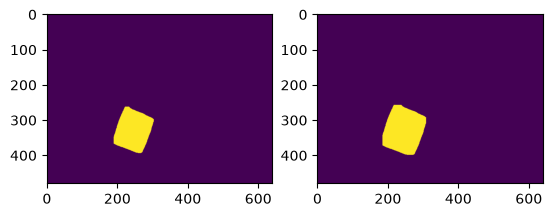

In [152]:
fig, ax = plt.subplots(1, 2)
ax[0].imshow(mask)
ax[1].imshow(padded_mask)

In [153]:
bounding_box_1 = filtered_pcd.get_oriented_bounding_box(robust=True)
bounding_box_2 = filtered_pcd.get_oriented_bounding_box()
bounding_box_3 = filtered_pcd.get_minimal_oriented_bounding_box()
bounding_box_1.color = [0.0, 1.0, 0.0]
bounding_box_2.color = [1.0, 0.0, 0.0]
bounding_box_3.color = [0.0, 0.0, 1.0]

In [ ]:
print("Launching Open3D visualizer window...")
o3d.visualization.draw_geometries(
    [complete_pcd, bounding_box_1, bounding_box_2, bounding_box_3,], 
    window_name="Masked 3D Point Cloud", 
    width=1024, 
    height=768, 
    left=50, top=50
)

Launching Open3D visualizer window...
[Open3D WARNING] [ViewControl] SetViewPoint() failed because window height and width are not set.
[Open3D WARNING] [ViewControl] SetViewPoint() failed because window height and width are not set.
[Open3D WARNING] [ViewControl] SetViewPoint() failed because window height and width are not set.
